# Data Analysis with Python

Phân tích khám phá (EDA) và trực quan hoá bằng Python để trả lời **RQ1**:
- Đo mức chênh lệch nhu cầu giữa các khu phố và tính chu kỳ theo lịch.
- Đánh giá tương quan giữa nhu cầu với thời tiết và hoạt động thi công đường phố.
- Kiểm định thống kê để so sánh khác biệt giữa các khu phố và các yếu tố liên quan.
- Vẽ biểu đồ phân phối, chuỗi thời gian theo khu phố và mùa vụ theo tháng, qua các năm.

**Dữ liệu đầu vào:** `SF_Tree_Weekly_Data_Cleaned.csv`, mỗi dòng là một khu phố trong một tuần.

## **1. Khởi tạo và nạp dữ liệu sạch**

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kruskal, mannwhitneyu

sns.set_style("ticks")
os.makedirs("../Outputs/figures", exist_ok=True)
os.makedirs("../Outputs/tables", exist_ok=True)

MAU = "#2E6DA4"   # một màu chính cho các biểu đồ chỉ có một chuỗi số liệu

# Đọc dữ liệu đã làm sạch
df = pd.read_csv("../Data/processed/SF_Tree_Weekly_Data_Cleaned.csv", parse_dates=["week_start"])
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25174 entries, 0 to 25173
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   nbhd            25174 non-null  object        
 1   week_start      25174 non-null  datetime64[ns]
 2   n               25174 non-null  int64         
 3   permits_active  25174 non-null  float64       
 4   PRCP            25174 non-null  float64       
 5   AWND            25174 non-null  float64       
 6   TMAX            25174 non-null  float64       
 7   so_cay          25174 non-null  int64         
 8   dbh_tb          25174 non-null  float64       
 9   tuoi_cay_tb     25174 non-null  float64       
 10  year            25174 non-null  int64         
 11  month           25174 non-null  int64         
 12  week_of_year    25174 non-null  int64         
dtypes: datetime64[ns](1), float64(6), int64(5), object(1)
memory usage: 2.5+ MB
None


In [2]:
# Bảng tổng hợp toàn thành phố theo tuần (thời tiết giống nhau ở mọi khu phố trong cùng một tuần)
city = df.groupby("week_start").agg(
    n=("n", "sum"),
    PRCP=("PRCP", "first"),
    AWND=("AWND", "first"),
    TMAX=("TMAX", "first"),
).reset_index()
city["year"] = city["week_start"].dt.year
city["month"] = city["week_start"].dt.month
city["n_tuan_toi"] = city["n"].shift(-1)   # số yêu cầu của tuần kế tiếp

print(city.shape)
city.head()

(614, 8)


,week_start,n,PRCP,AWND,TMAX,year,month,n_tuan_toi
0,2015-01-05,140,0.0,2.3,15.485714,2015,1,105.0
1,2015-01-12,105,0.0,1.9,15.542857,2015,1,95.0
2,2015-01-19,95,0.0,2.0,16.828571,2015,1,108.0
3,2015-01-26,108,0.0,2.7,19.057143,2015,1,412.0
4,2015-02-02,412,51.0,11.0,18.400000,2015,2,215.0


## **2. Phân phối nhu cầu**

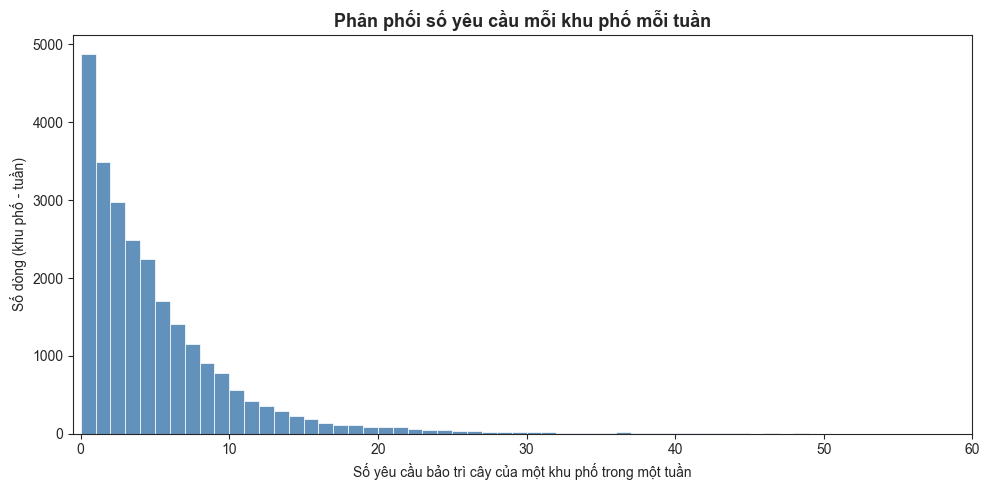

Tỷ lệ tuần bằng 0 : 19.4%
Trung vị          : 3
Trung bình        : 4.61
Lớn nhất          : 99
Độ lệch (skewness): 3.42


In [3]:
# Phân phối số yêu cầu mỗi khu phố mỗi tuần
plt.figure(figsize=(10, 5))
sns.histplot(df["n"], binwidth=1, color=MAU)
plt.xlim(-0.5, 60)
plt.xlabel("Số yêu cầu bảo trì cây của một khu phố trong một tuần")
plt.ylabel("Số dòng (khu phố - tuần)")
plt.title("Phân phối số yêu cầu mỗi khu phố mỗi tuần", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_01_distribution_n.png", dpi=300)
plt.show()

print(f"Tỷ lệ tuần bằng 0 : {(df['n'] == 0).mean() * 100:.1f}%")
print(f"Trung vị          : {df['n'].median():.0f}")
print(f"Trung bình        : {df['n'].mean():.2f}")
print(f"Lớn nhất          : {df['n'].max()}")
print(f"Độ lệch (skewness): {df['n'].skew():.2f}")

**Nhận xét:** Phân phối số yêu cầu mỗi khu phố mỗi tuần

**Vì sao dùng biểu đồ này?** Histogram với mỗi cột rộng đúng 1 đơn vị cho thấy rõ có bao nhiêu tuần có 0, 1, 2... yêu cầu. Trục ngang cắt ở 60 để phần chính không bị ép nhỏ.

**Kết quả cần đọc:**
- Phân phối **lệch phải mạnh** (độ lệch 3.42): phần lớn các tuần chỉ có vài yêu cầu, **trung vị 3**, trung bình **4.61**.
- **19.4%** số tuần không có yêu cầu nào (cột cao nhất ở số 0).
- Có một số ít tuần rất cao, lớn nhất **99 yêu cầu** (nằm ngoài khung biểu đồ) — chính là các tuần bão.
- → Dữ liệu không phân phối chuẩn, nên ở các phần sau dùng **tương quan Spearman** và **kiểm định phi tham số**.

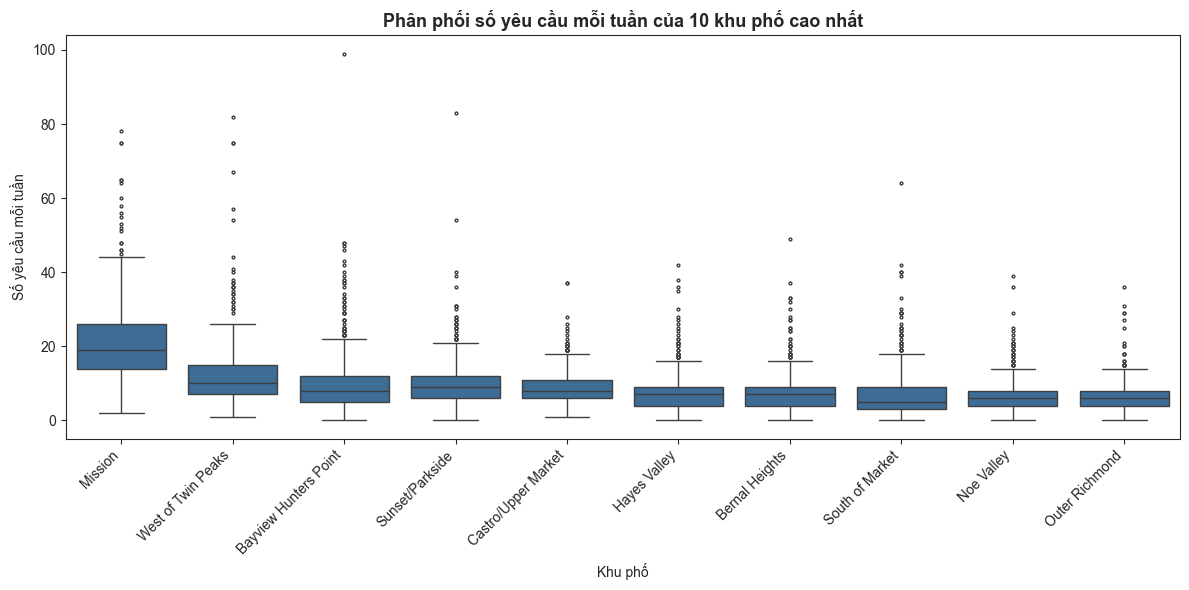

In [4]:
# Boxplot số yêu cầu mỗi tuần của 10 khu phố có tổng nhu cầu cao nhất
top10 = df.groupby("nbhd")["n"].sum().sort_values(ascending=False).head(10).index

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[df["nbhd"].isin(top10)], x="nbhd", y="n", order=top10, color=MAU, fliersize=2)
plt.xlabel("Khu phố")
plt.ylabel("Số yêu cầu mỗi tuần")
plt.title("Phân phối số yêu cầu mỗi tuần của 10 khu phố cao nhất", fontsize=13, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_02_boxplot_top10_nbhd.png", dpi=300)
plt.show()

**Nhận xét:** Phân phối số yêu cầu mỗi tuần theo khu phố

**Vì sao dùng biểu đồ này?** Boxplot cho thấy cả mức thông thường (đường giữa hộp là trung vị) lẫn các tuần đột biến (các chấm phía trên) của từng khu phố — điều mà con số tổng ở Notebook 3 không thể hiện được.

**Kết quả cần đọc:**
- **Mission** cao hơn hẳn: một tuần bình thường khoảng **19 yêu cầu** (trung vị), trong khi các khu còn lại chỉ khoảng **5–10 yêu cầu**.
- **Khu phố nào cũng có các tuần đột biến** vượt xa mức thông thường; tuần cao nhất (**99 yêu cầu**) thuộc về Bayview Hunters Point chứ không phải Mission.
- → Mức nền khác nhau giữa các khu phố, nhưng **các đợt tăng vọt xảy ra ở mọi nơi** — mô hình dự báo cần học được cả hai điều này.

## **3. Chuỗi thời gian nhu cầu**

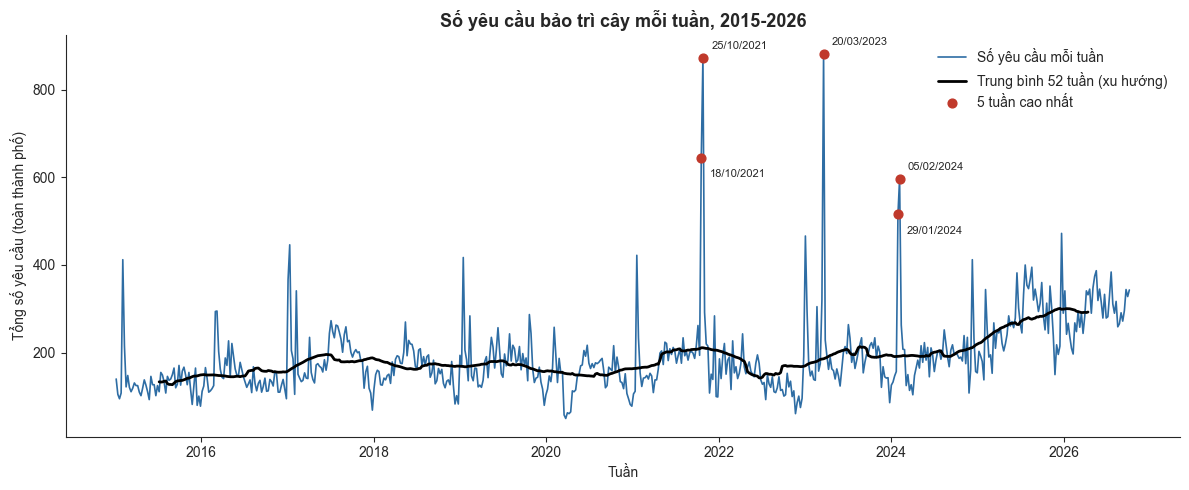

In [5]:
# Tổng số yêu cầu mỗi tuần toàn thành phố, đánh dấu 5 tuần cao nhất
top5_weeks = city.nlargest(5, "n")

plt.figure(figsize=(12, 5))
plt.plot(city["week_start"], city["n"], color=MAU, linewidth=1.2, label="Số yêu cầu mỗi tuần")
plt.plot(city["week_start"], city["n"].rolling(52, center=True).mean(), color="black",
         linewidth=2, label="Trung bình 52 tuần (xu hướng)")
plt.scatter(top5_weeks["week_start"], top5_weeks["n"], color="#C0392B", s=40, zorder=3, label="5 tuần cao nhất")
for _, r in top5_weeks.iterrows():
    # nếu có tuần cao điểm khác cao hơn nằm sát bên (trong 14 ngày) thì đặt nhãn xuống dưới để không chồng chữ
    gan = top5_weeks[(abs(top5_weeks["week_start"] - r["week_start"]).dt.days <= 14) & (top5_weeks["n"] > r["n"])]
    dy = -14 if len(gan) > 0 else 6
    plt.annotate(r["week_start"].strftime("%d/%m/%Y"), (r["week_start"], r["n"]),
                 textcoords="offset points", xytext=(6, dy), fontsize=8)
sns.despine()
plt.xlabel("Tuần")
plt.ylabel("Tổng số yêu cầu (toàn thành phố)")
plt.title("Số yêu cầu bảo trì cây mỗi tuần, 2015-2026", fontsize=13, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_03_weekly_city_trend.png", dpi=300)
plt.show()

**Nhận xét:** Chuỗi thời gian nhu cầu toàn thành phố

**Vì sao dùng biểu đồ này?** Biểu đồ đường theo tuần cho thấy cùng lúc **xu hướng dài hạn** (đường đen, trung bình 52 tuần) và **các đợt tăng vọt ngắn hạn** (điểm đỏ) — đúng đơn vị tuần của bài toán dự báo.

**Kết quả cần đọc:**
- **Xu hướng** tăng từ khoảng **140 yêu cầu/tuần (2015)** lên khoảng **300 yêu cầu/tuần (2026)**; đi ngang giai đoạn 2018–2024 rồi **tăng mạnh từ 2025**.
- **5 tuần cao nhất** đều là các đợt **bão**: tháng 10/2021, tháng 3/2023 và đầu tháng 2/2024, cao gấp **3–4 lần** mức thông thường.
- Các tuần bão thường đi thành **cặp liền nhau** (18/10 và 25/10/2021; 29/01 và 05/02/2024) → bão ảnh hưởng kéo dài sang cả tuần sau.
- → Mô hình cần học cả **xu hướng tăng** và **các đột biến do bão**; đột biến là phần khó dự báo nhất.

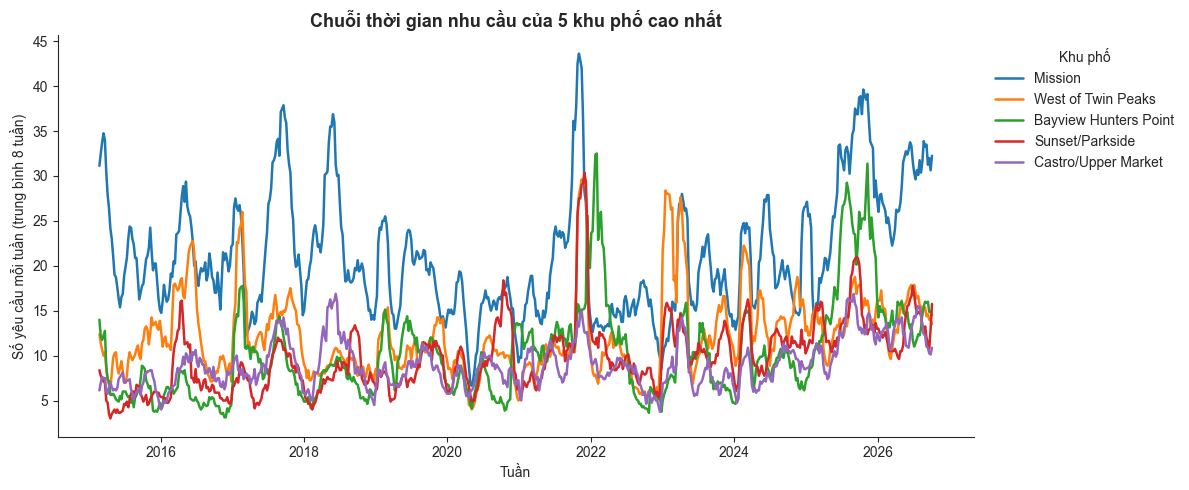

In [6]:
# Chuỗi thời gian của 5 khu phố có nhu cầu cao nhất (trung bình trượt 8 tuần cho dễ nhìn)
top5_nbhd = df.groupby("nbhd")["n"].sum().sort_values(ascending=False).head(5).index
colors = sns.color_palette("tab10", 5)

plt.figure(figsize=(12, 5))
for color, nb in zip(colors, top5_nbhd):
    s = df[df["nbhd"] == nb].set_index("week_start")["n"].rolling(8).mean()
    plt.plot(s.index, s.values, color=color, linewidth=1.8, label=nb)
sns.despine()
plt.xlabel("Tuần")
plt.ylabel("Số yêu cầu mỗi tuần (trung bình 8 tuần)")
plt.title("Chuỗi thời gian nhu cầu của 5 khu phố cao nhất", fontsize=13, fontweight="bold")
plt.legend(title="Khu phố", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_04_timeseries_top5_nbhd.png", dpi=300)
plt.show()

**Nhận xét:** Chuỗi thời gian nhu cầu của 5 khu phố cao nhất

**Vì sao dùng biểu đồ này?** So sánh diễn biến theo thời gian của 5 khu phố trên cùng một trục; dùng trung bình 8 tuần để làm mượt dao động từng tuần, giúp thấy rõ xu hướng và các đợt tăng chung.

**Kết quả cần đọc:**
- **Mission luôn cao hơn hẳn** các khu khác (thường 15–40 yêu cầu/tuần so với 5–20), và tăng rõ từ **2025**.
- Các khu phố **tăng vọt cùng một lúc** (cuối 2021, đầu 2023, đầu 2024) → nguyên nhân chung cho cả thành phố là **bão**, không phải chuyện riêng của từng khu.
- → Mỗi khu phố có **mức nền riêng**, nhưng **cùng chịu tác động** của thời tiết; mô hình cần dùng cả thông tin khu phố lẫn thông tin chung của thành phố.

## **4. Mùa vụ theo tháng và qua các năm**

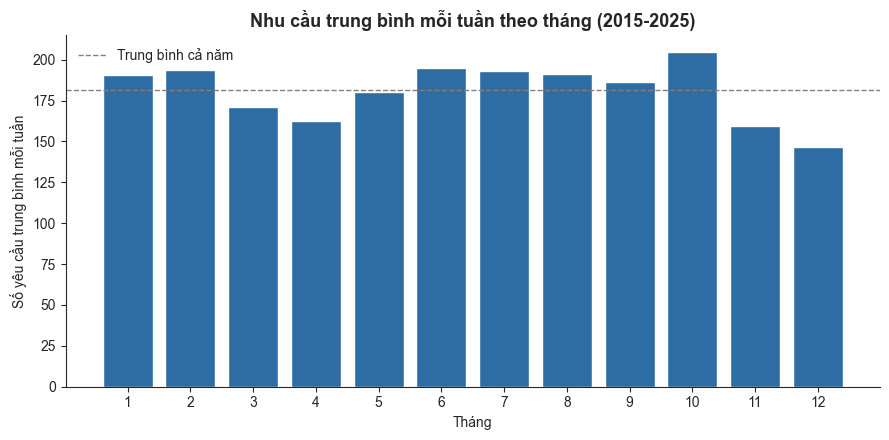

In [7]:
# Trung bình số yêu cầu mỗi tuần (toàn thành phố) theo tháng, chỉ các năm đủ 12 tháng (2015-2025)
month_avg = city[city["year"] <= 2025].groupby("month")["n"].mean()

plt.figure(figsize=(9, 4.5))
plt.bar(month_avg.index, month_avg.values, color=MAU)
plt.axhline(month_avg.mean(), color="gray", linestyle="--", linewidth=1, label="Trung bình cả năm")
sns.despine()
plt.xticks(range(1, 13))
plt.xlabel("Tháng")
plt.ylabel("Số yêu cầu trung bình mỗi tuần")
plt.title("Nhu cầu trung bình mỗi tuần theo tháng (2015-2025)", fontsize=13, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_05_avg_by_month.png", dpi=300)
plt.show()

**Nhận xét:** Nhu cầu trung bình mỗi tuần theo tháng

**Vì sao dùng biểu đồ này?** Trực quan hoá lại truy vấn 6 (Notebook 3), thêm đường **trung bình cả năm** (khoảng 181 yêu cầu/tuần) để thấy ngay tháng nào cao hơn hay thấp hơn mức thông thường. Chỉ dùng các năm đủ 12 tháng (2015–2025).

**Kết quả cần đọc:**
- **Cao hơn trung bình:** tháng **1–2** và **6–10**, cao nhất là **tháng 10** (khoảng 205).
- **Thấp hơn trung bình:** tháng **3–4** và **11–12**, thấp nhất là **tháng 12** (khoảng 146).
- Lưu ý: mức cao của **tháng 10** chủ yếu do trận bão tháng 10/2021 (xem heatmap bên dưới), không phải quy luật lặp lại hằng năm.
- → Nhu cầu cao hơn vào **tháng 1–2** và **mùa hè – đầu thu**; **cuối năm (tháng 11–12)** luôn thấp nhất.

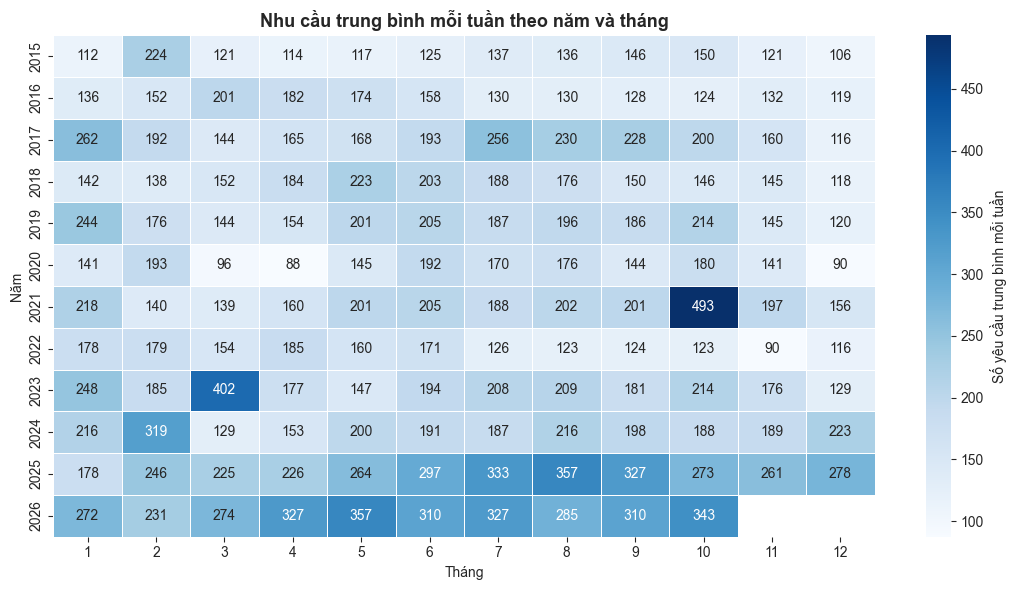

In [8]:
# Heatmap năm x tháng: trung bình số yêu cầu mỗi tuần (toàn thành phố)
pivot = city.pivot_table(index="year", columns="month", values="n", aggfunc="mean")

plt.figure(figsize=(11, 6))
sns.heatmap(pivot, cmap="Blues", annot=True, fmt=".0f", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Số yêu cầu trung bình mỗi tuần"})
plt.xlabel("Tháng")
plt.ylabel("Năm")
plt.title("Nhu cầu trung bình mỗi tuần theo năm và tháng", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_06_heatmap_year_month.png", dpi=300)
plt.show()

**Nhận xét:** Nhu cầu trung bình mỗi tuần theo năm và tháng

**Vì sao dùng biểu đồ này?** Heatmap đặt năm theo hàng, tháng theo cột nên đọc được cùng lúc **xu hướng qua các năm** (màu đậm dần từ trên xuống) và **mùa vụ trong năm** (theo từng cột); các ô đậm bất thường chỉ ra những tháng có sự kiện đặc biệt.

**Kết quả cần đọc:**
- **Xu hướng tăng rõ**: hàng 2025–2026 đậm hơn hẳn các năm trước (phần lớn trên **250 yêu cầu/tuần**).
- **Các ô đậm nhất là tháng có bão**: **10/2021 (493)**, **3/2023 (402)**, **2/2024 (319)**.
- **Tháng 10 cao nhất** ở biểu đồ theo tháng chủ yếu do **một trận bão năm 2021**; bỏ năm này ra, tháng 10 chỉ ở mức trung bình (khoảng 181).
- **Tháng 3–4/2020** thấp bất thường (**96, 88**) — trùng thời điểm **phong tỏa COVID-19**.
- **Tháng 12** thấp ở hầu hết các năm → đây mới là quy luật mùa vụ ổn định.

## **5. Chênh lệch nhu cầu giữa các khu phố**

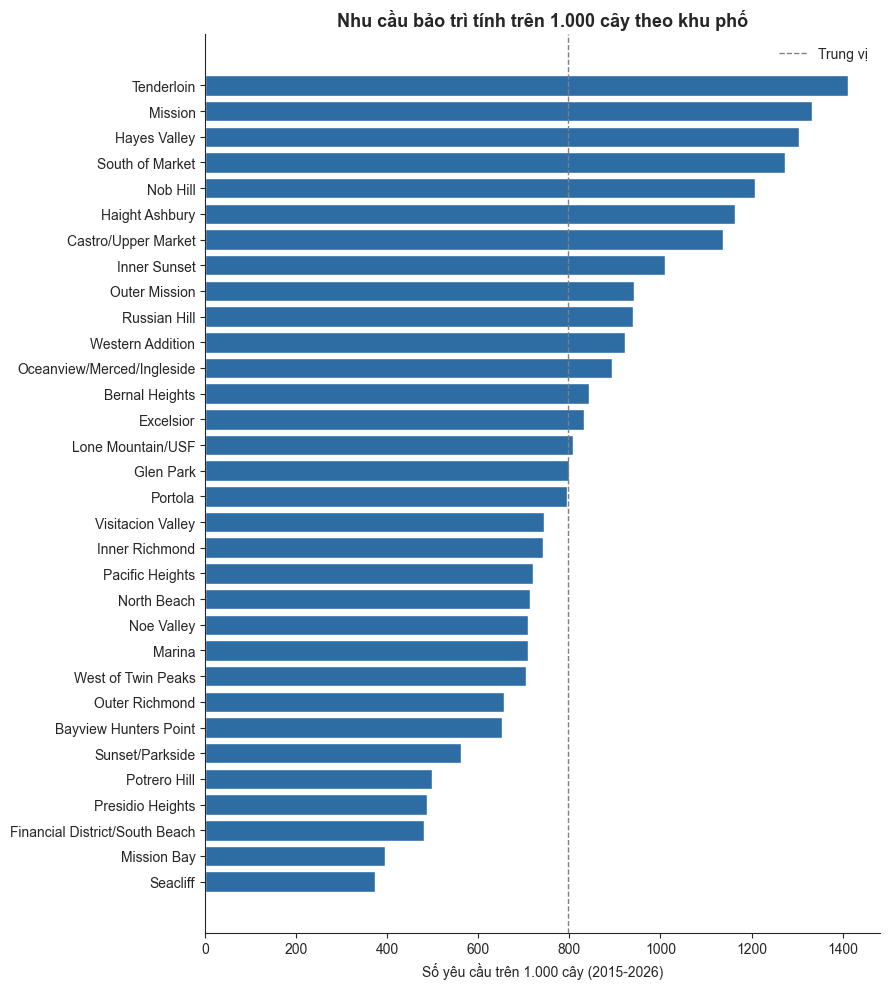

Số khu phố: 32
Cao nhất / thấp nhất: 3.8 lần


In [9]:
# Số yêu cầu trên 1.000 cây của mọi khu phố có từ 1.000 cây (như truy vấn 3, Notebook 3)
nb = df.groupby("nbhd").agg(tong=("n", "sum"), so_cay=("so_cay", "first")).reset_index()
nb = nb[nb["so_cay"] >= 1000].copy()
nb["tren_1000_cay"] = nb["tong"] * 1000 / nb["so_cay"]
nb = nb.sort_values("tren_1000_cay")

plt.figure(figsize=(9, 10))
plt.barh(nb["nbhd"], nb["tren_1000_cay"], color=MAU)
plt.axvline(nb["tren_1000_cay"].median(), color="gray", linestyle="--", linewidth=1, label="Trung vị")
sns.despine()
plt.xlabel("Số yêu cầu trên 1.000 cây (2015-2026)")
plt.ylabel("")
plt.title("Nhu cầu bảo trì tính trên 1.000 cây theo khu phố", fontsize=13, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_07_per_1000_trees.png", dpi=300)
plt.show()

print(f"Số khu phố: {len(nb)}")
print(f"Cao nhất / thấp nhất: {nb['tren_1000_cay'].max() / nb['tren_1000_cay'].min():.1f} lần")

**Nhận xét:** Nhu cầu tính trên 1.000 cây theo khu phố

**Vì sao dùng biểu đồ này?** Notebook 3 chỉ xem top 10; biểu đồ cột ngang này xếp **toàn bộ 32 khu phố** có từ 1.000 cây để thấy mức chênh lệch đầy đủ, kèm đường **trung vị** (khoảng 800 yêu cầu/1.000 cây) làm mốc so sánh.

**Kết quả cần đọc:**
- Nhóm cao nhất là **các khu trung tâm đông đúc**: Tenderloin, Mission, Hayes Valley, South of Market (khoảng **1,270–1,410**).
- Nhóm thấp nhất là **khu mới hoặc khu thương mại**: Seacliff, Mission Bay, Financial District (dưới **500**).
- Khu cao nhất gấp khoảng **3.8 lần** khu thấp nhất.
- **West of Twin Peaks, Bayview Hunters Point, Sunset/Parkside** — nhiều yêu cầu nhất về tổng số — đều **nằm dưới trung vị** khi tính theo số cây.

## **6. Tương quan với thời tiết và hoạt động thi công**

Thời tiết là **một giá trị chung cho cả thành phố** mỗi tuần, nên tương quan với thời tiết được tính ở **cấp toàn thành phố** (tổng số yêu cầu mỗi tuần), không tính trên từng khu phố. Dùng hệ số **Spearman** vì số yêu cầu bị lệch phải mạnh, không phân phối chuẩn.

In [10]:
# Tương quan giữa thời tiết của tuần hiện tại với số yêu cầu tuần hiện tại và tuần kế tiếp
rows = []
for col in ["PRCP", "AWND", "TMAX"]:
    rho_same, p_same = spearmanr(city["n"], city[col])
    sub = city.dropna(subset=["n_tuan_toi"])
    rho_next, p_next = spearmanr(sub["n_tuan_toi"], sub[col])
    rows.append({"bien_thoi_tiet": col,
                 "rho_cung_tuan": round(rho_same, 3), "p_cung_tuan": round(p_same, 4),
                 "rho_tuan_toi": round(rho_next, 3), "p_tuan_toi": round(p_next, 4)})

corr_weather = pd.DataFrame(rows)
corr_weather

,bien_thoi_tiet,rho_cung_tuan,p_cung_tuan,rho_tuan_toi,p_tuan_toi
0,PRCP,-0.059,0.1461,-0.127,0.0016
1,AWND,0.258,0.0000,0.164,0.0000
2,TMAX,0.218,0.0000,0.213,0.0000


**Nhận xét:** Tương quan giữa thời tiết và nhu cầu

**Vì sao dùng phân tích này?** Truy vấn 8 (Notebook 3) cho thấy các tuần cao điểm gắn với bão. Bảng này kiểm tra bằng số trên **toàn bộ 614 tuần**: so sánh tương quan Spearman của thời tiết tuần này với nhu cầu **cùng tuần** và **tuần tới**.

**Kết quả cần đọc:**
- **Gió** có tương quan rõ nhất (**0.26** cùng tuần, **0.16** tuần tới): tuần gió mạnh thì nhu cầu cao hơn.
- **Mưa** gần như không tương quan, thậm chí hơi âm (**−0.13** với tuần tới) — vì San Francisco gần như không mưa vào **mùa hè**, đúng lúc nhu cầu cao; **nhiệt độ** tương quan dương (**0.21–0.22**) cũng chỉ phản ánh mùa.
- → Xét trung bình mọi tuần, thời tiết chỉ liên quan **yếu** đến nhu cầu; tác động của mưa chỉ thể hiện ở **các trận bão lớn** (hiếm), sẽ được kiểm định riêng ở **mục 7**.

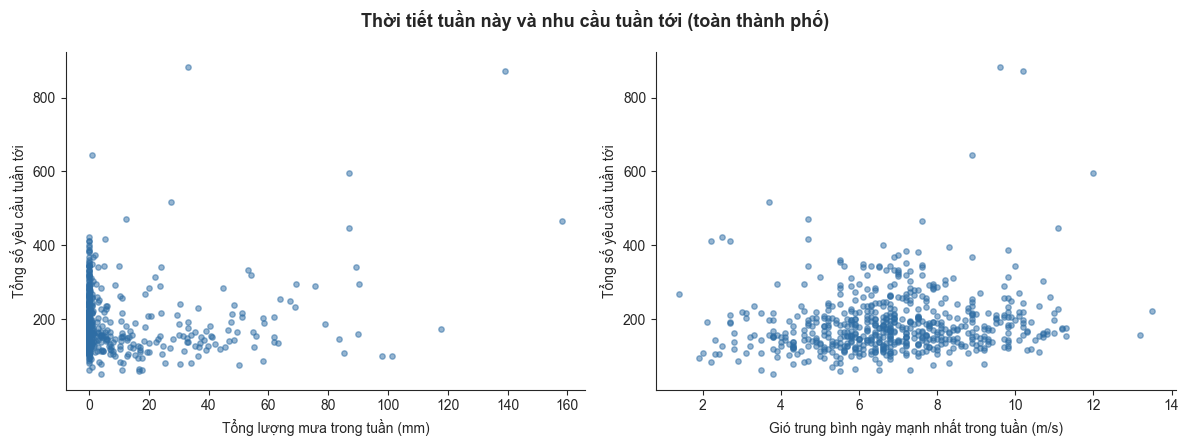

In [11]:
# Biểu đồ phân tán: thời tiết tuần này và tổng số yêu cầu tuần tới
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in zip(axes, ["PRCP", "AWND"],
                          ["Tổng lượng mưa trong tuần (mm)", "Gió trung bình ngày mạnh nhất trong tuần (m/s)"]):
    ax.scatter(city[col], city["n_tuan_toi"], color=MAU, alpha=0.5, s=15)
    ax.set_xlabel(label)
    ax.set_ylabel("Tổng số yêu cầu tuần tới")
    sns.despine(ax=ax)
fig.suptitle("Thời tiết tuần này và nhu cầu tuần tới (toàn thành phố)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_08_weather_vs_next_week.png", dpi=300)
plt.show()

**Nhận xét:** Thời tiết tuần này và nhu cầu tuần tới

**Vì sao dùng biểu đồ này?** Biểu đồ phân tán cho thấy **hình dạng** quan hệ mà một hệ số tương quan không thể hiện được — đặc biệt là các tuần bão hiếm nhưng có tác động lớn.

**Kết quả cần đọc:**
- **Lượng mưa:** phần lớn các tuần **không mưa** (cột dày ở mức 0) nhưng nhu cầu tuần tới vẫn dao động rất rộng (khoảng 50–420); các tuần mưa nhiều **không phải lúc nào** cũng kéo nhu cầu tăng (có tuần mưa trên 100 mm nhưng nhu cầu tuần tới chỉ khoảng 100).
- Chỉ vài **trận bão lớn** tạo ra các điểm vọt lên trên 450 (ví dụ tuần mưa **139 mm** → tuần tới **873 yêu cầu**).
- **Gió:** các điểm trải đều từ 2–12 m/s, xu hướng tăng **nhẹ**; các tuần cao điểm nhất đều có gió **khoảng 9–12 m/s**.
- → Thời tiết **không quyết định** nhu cầu ở các tuần bình thường; tác động chỉ rõ ở **những tuần thời tiết cực đoan**.

In [12]:
# Tương quan giữa số giấy phép thi công và nhu cầu: so sánh GIỮA các khu phố và BÊN TRONG từng khu phố
# (a) Giữa các khu phố: mỗi khu phố là 1 điểm (giá trị trung bình) -> 41 điểm
by_nb = df.groupby("nbhd")[["permits_active", "n"]].mean()
rho_between, p_between = spearmanr(by_nb["permits_active"], by_nb["n"])

# (b) Bên trong từng khu phố: trừ đi trung bình của chính khu phố đó, chỉ giữ phần thay đổi theo thời gian
dm = df[["nbhd", "permits_active", "n"]].copy()
dm["permits_dm"] = dm["permits_active"] - dm.groupby("nbhd")["permits_active"].transform("mean")
dm["n_dm"] = dm["n"] - dm.groupby("nbhd")["n"].transform("mean")
rho_within, p_within = spearmanr(dm["permits_dm"], dm["n_dm"])

corr_permits = pd.DataFrame({
    "cach_tinh": ["Giữa các khu phố (41 điểm)", "Bên trong từng khu phố"],
    "spearman_rho": [round(rho_between, 3), round(rho_within, 3)],
    "p_value": [round(p_between, 4), round(p_within, 4)],
})
corr_permits

,cach_tinh,spearman_rho,p_value
0,Giữa các khu phố (41 điểm),0.644,0.0
1,Bên trong từng khu phố,0.063,0.0


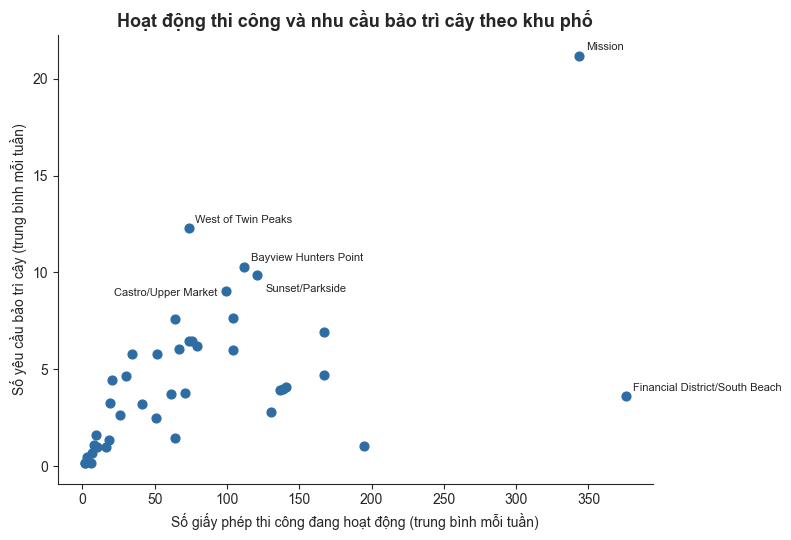

In [13]:
# Biểu đồ phân tán giữa các khu phố: số giấy phép trung bình và số yêu cầu trung bình
plt.figure(figsize=(8, 5.5))
plt.scatter(by_nb["permits_active"], by_nb["n"], color=MAU, s=40)
ten_nhan = list(by_nb["n"].nlargest(5).index) + list(by_nb["permits_active"].nlargest(2).index)
vi_tri = {"Castro/Upper Market": (-6, -4, "right"),   # nhãn sang bên trái điểm
          "Sunset/Parkside":     (6, -12, "left")}     # nhãn xuống dưới điểm
for name in dict.fromkeys(ten_nhan):
    dx, dy, ha = vi_tri.get(name, (5, 4, "left"))
    plt.annotate(name, (by_nb.loc[name, "permits_active"], by_nb.loc[name, "n"]),
                 textcoords="offset points", xytext=(dx, dy), ha=ha, fontsize=8)
sns.despine()
plt.xlabel("Số giấy phép thi công đang hoạt động (trung bình mỗi tuần)")
plt.ylabel("Số yêu cầu bảo trì cây (trung bình mỗi tuần)")
plt.title("Hoạt động thi công và nhu cầu bảo trì cây theo khu phố", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_09_permits_vs_n_by_nbhd.png", dpi=300)
plt.show()

**Nhận xét:** Tương quan giữa hoạt động thi công và nhu cầu

**Vì sao dùng phân tích này?** Khu phố sầm uất thường vừa nhiều giấy phép thi công vừa nhiều yêu cầu bảo trì, nên tách làm 2 cách: **giữa các khu phố** (khu nhiều thi công có nhiều yêu cầu hơn không?) và **bên trong từng khu phố** (khi thi công trong một khu tăng lên thì yêu cầu ở chính khu đó có tăng theo không?). Biểu đồ phân tán minh hoạ cách thứ nhất, mỗi điểm là một khu phố.

**Kết quả cần đọc:**
- **Giữa các khu phố:** tương quan **khá mạnh (0.644)** — nhìn chung khu nhiều thi công cũng là khu nhiều yêu cầu (các điểm đi lên từ trái sang phải).
- **Bên trong từng khu phố:** gần như **không có tương quan (0.063)**; p-value nhỏ chỉ do dữ liệu rất lớn (25 nghìn dòng), mức độ quá yếu để có ý nghĩa thực tế.
- **Financial District/South Beach** có nhiều giấy phép thi công nhất (khoảng **375**) nhưng chỉ khoảng **3.6 yêu cầu/tuần** — khu thương mại, nhiều công trình nhưng ít cây đường phố; ngược lại **West of Twin Peaks** ít thi công (khoảng 75) nhưng nhiều yêu cầu (khoảng **12/tuần**).
- → Giấy phép thi công chủ yếu phản ánh **khu phố nào đông đúc**, chứ **không trực tiếp làm tăng** nhu cầu bảo trì cây. Notebook 5 sẽ kiểm tra biến này có thật sự giúp mô hình dự báo tốt hơn không.

## **7. Kiểm định thống kê**

Dùng kiểm định **phi tham số** (không giả định phân phối chuẩn) vì số yêu cầu bị lệch phải mạnh.

In [14]:
# Kiểm định 1 (Kruskal-Wallis): số yêu cầu mỗi tuần có khác nhau giữa các khu phố không?
groups = [g["n"].values for _, g in df.groupby("nbhd")]
stat_kw, p_kw = kruskal(*groups)
print(f"Kiểm định Kruskal-Wallis giữa {len(groups)} khu phố")
print(f"  H = {stat_kw:.1f}, p-value = {p_kw:.2e}")

# Kiểm định 2 (Mann-Whitney U): tuần sau một tuần mưa lớn có nhiều yêu cầu hơn tuần sau một tuần không mưa không?
# "Tuần mưa lớn" = 10% số tuần có tổng lượng mưa cao nhất
sub = city.dropna(subset=["n_tuan_toi"])
nguong = sub["PRCP"].quantile(0.9)
sau_mua_lon = sub.loc[sub["PRCP"] >= nguong, "n_tuan_toi"]
sau_khong_mua = sub.loc[sub["PRCP"] == 0, "n_tuan_toi"]
stat_mw, p_mw = mannwhitneyu(sau_mua_lon, sau_khong_mua, alternative="greater")

print("\nKiểm định Mann-Whitney U: nhu cầu tuần tới sau tuần mưa lớn và sau tuần không mưa")
print(f"  Ngưỡng tuần mưa lớn : >= {nguong:.1f} mm/tuần")
print(f"  Sau tuần mưa lớn    : {len(sau_mua_lon)} tuần, trung vị {sau_mua_lon.median():.0f} yêu cầu")
print(f"  Sau tuần không mưa  : {len(sau_khong_mua)} tuần, trung vị {sau_khong_mua.median():.0f} yêu cầu")
print(f"  U = {stat_mw:.0f}, p-value = {p_mw:.2e}")

Kiểm định Kruskal-Wallis giữa 41 khu phố
  H = 14648.9, p-value = 0.00e+00

Kiểm định Mann-Whitney U: nhu cầu tuần tới sau tuần mưa lớn và sau tuần không mưa
  Ngưỡng tuần mưa lớn : >= 33.0 mm/tuần
  Sau tuần mưa lớn    : 64 tuần, trung vị 166 yêu cầu
  Sau tuần không mưa  : 352 tuần, trung vị 180 yêu cầu
  U = 10561, p-value = 7.87e-01


**Nhận xét:** Kiểm định thống kê

**Vì sao dùng các kiểm định này?**
- **Kruskal-Wallis** kiểm tra xem số yêu cầu mỗi tuần có thật sự khác nhau giữa 41 khu phố hay chỉ do ngẫu nhiên.
- **Mann-Whitney U** kiểm tra xem tuần ngay sau một **tuần mưa lớn** (10% tuần mưa nhiều nhất, từ 33 mm/tuần) có nhiều yêu cầu hơn tuần sau một **tuần không mưa** hay không.
- Dùng kiểm định **phi tham số** vì số yêu cầu bị lệch phải mạnh; p-value < 0.05 thì khác biệt có ý nghĩa thống kê.

**Kết quả cần đọc:**
- **Kruskal-Wallis:** p-value gần bằng 0 → nhu cầu **khác biệt rõ rệt giữa các khu phố**, khẳng định kết quả ở Notebook 3.
- **Mann-Whitney U:** p-value = **0.79** → **không có bằng chứng** mưa lớn làm tăng nhu cầu tuần sau; trung vị sau tuần mưa lớn (**166**) thậm chí thấp hơn sau tuần không mưa (**180**), vì tuần không mưa phần lớn rơi vào **mùa hè** — mùa nhu cầu cao.
- → Lượng mưa nói chung **không phải yếu tố dự báo đáng tin cậy**; đột biến nhu cầu chỉ gắn với **một số ít trận bão cực đoan** (mưa lớn kèm gió mạnh), là phần khó dự báo nhất ở Notebook 5.

## **8. Xuất bảng kết quả**

In [15]:
corr_weather.to_csv("../Outputs/tables/eda_01_corr_weather.csv", index=False)
corr_permits.to_csv("../Outputs/tables/eda_02_corr_permits.csv", index=False)
nb.sort_values("tren_1000_cay", ascending=False).to_csv("../Outputs/tables/eda_03_per_1000_trees.csv", index=False)
pd.DataFrame({
    "kiem_dinh": ["Kruskal-Wallis (41 khu phố)", "Mann-Whitney U (sau tuần mưa lớn > sau tuần không mưa)"],
    "thong_ke": [round(stat_kw, 1), round(stat_mw, 0)],
    "p_value": [p_kw, p_mw],
}).to_csv("../Outputs/tables/eda_04_tests.csv", index=False)

print("Đã lưu xong 9 biểu đồ và 4 bảng kết quả EDA.")

Đã lưu xong 9 biểu đồ và 4 bảng kết quả EDA.
